<a href="https://colab.research.google.com/github/shiv33-s/googlecolpy/blob/main/exp3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic regression
###Step1: Data Collection
Importing libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [ ]:
titanic_data = pd.read_csv('/content/titanic_data (1).csv')

In [ ]:
titanic_data.head()

In [ ]:
print(str(len(titanic_data.index)))# total no of passengers in orignal data

### Step 2 : Analyzing the data

!!! knowing the data !!! plotting graphs !!! EDA

In [ ]:
#knowing how many people survived and died
sns.countplot(x='Survived',data=titanic_data)

In [ ]:
#knowing howmany male survided and how many females survived sns. countplot(x='Survived',hue='Sex',data-titanic_data)

In [ ]:
#Knowing which class people survived the most sns. countplot(x='Survived',hue='Pclass',data=titanic_data)

In [ ]:
#Age distribution
titanic_data['Age'].plot.hist()

In [ ]:
#fare- the amount of money a passenger paid for their tickit
titanic_data['Fare'].plot.hist(figsize=(8,4))

Exploratory data Analysis

In [ ]:
titanic_data.info()

### Step 3 : Data Preprocessing

!!! Data cleaning (Removing impurities) !!! Imputation

In [ ]:
titanic_data.isnull()

In [ ]:
titanic_data.isnull().sum()

In [ ]:
#imputation
titanic_data.drop('Cabin',axis=1,inplace=True)

In [ ]:
titanic_data.head(2)

In [ ]:
titanic_data.dropna(inplace=True)

In [ ]:
titanic_data.isnull().sum()

Converting data from one form to another

In [ ]:
titanic_data.head(5)
# we will first convert categorical variables into dummy variabls and then use them as logistic reg only takes 2 inputs

Encoding

Using logistic regression we will predict how many people survived and how many died in titanic ship. here 1 survived and 0 died.

In [ ]:
pd.get_dummies(titanic_data['Sex']).astype(int)

In [ ]:
S = pd.get_dummies(titanic_data['Sex'],drop_first=True).astype(int)
S.head(4)

In [ ]:
#conversion of Embarked column from one form to another
#Q= Quinstown, S=southam , C= chambor
E = pd.get_dummies(titanic_data['Embarked'],drop_first=True).astype(int).astype(int)
E.head(4)

In [ ]:
#conversion of Pclass column from one form to another
P = pd.get_dummies(titanic_data['Pclass'],drop_first=True).astype(int).astype(int)
P.head(4)

In [ ]:
#concatinate all the new rows in the dataset
titanic_data = pd.concat([titanic_data,S,E,P],axis=1)

In [ ]:
titanic_data.drop(['Sex','Embarked','PassengerId','Name','Ticket','Pclass'],axis=1,inplace=True)

In [ ]:
#our final dataset
titanic_data.head(5)

### Step 4 : Split Training and testing the data

Train Data

In [ ]:
X = titanic_data.drop('Survived',axis=1)# accept survived all the other columns are indep var
y = titanic_data['Survived']

splitting the data

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1)

Implementing logistic regression

!!! Creating our Model

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
model = LogisticRegression()

In [ ]:
X_train.columns = X_train.columns.astype(str)
model.fit(X_train,y_train)

In [ ]:
X_test.columns = X_test.columns.astype(str)
predictions = model.predict(X_test)

### Step 5 : Predictions

In [ ]:
print("Predictions:")
print(predictions)

Predictions:
[1 0 0 1 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 1 1 1 0 1 0
 1 0 0 0 0 0 1 1 0 0 0 1 0 1 0 0 0 0 1 0 0 1 1 1 1 0 0 1 0 1 0 1 1 0 1 0 0
 1 1 1 1 0 1 1 0 1 1 1 0 0 0 1 0 1 1 1 0 0 0 0 0 1 0 0 1 0 1 0 1 0 0 1 1 0
 0 1 0 0 0 1 0 1 0 0 0 0 0 0 1 1 0 0 1 1 1 0 0 1 0 0 0 0 1 0 1 0 1 0 0 1 1
 0 0 1 0 0 0 0 1 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 1 0 0 1 0 1 1 0 0 0 0 1 1 0
 0 1 0 0 1 1 1 0 0 0 0 0 1 1 1 1 0 0 0 0 0 0 1 0 1 0 0 0 0]


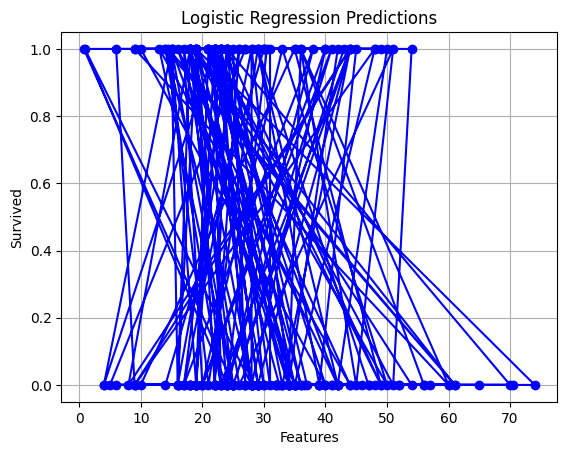

In [ ]:
import matplotlib.pyplot as plt

# Assuming you already have your trained model and test data
# model.fit(X_train, y_train)
predictions = model.predict(X_test)

# Plot predicted classes vs the first feature of X_test
plt.plot(X_test.iloc[:, 0], predictions, marker='o', linestyle='-', color='blue')
plt.xlabel('Features')
plt.ylabel('Survived')
plt.title('Logistic Regression Predictions')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
print(confusion_matrix(y_test,predictions))

[[102  24]
 [ 25  63]]


Step 6 : Checking the Accuracy

In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
accuracy_score(y_test,predictions)

0.7710280373831776